# Experimento 10 — Benchmark de classificadores (versão refatorada)
**Objetivo:** comparar Random Forest, Extra Trees, HistGradientBoosting e Regressão Logística, com as mesmas 4 features e validação interna equivalente.

**Mudanças:** descoberta de arquivos por pastas homônimas no Drive, escolha explícita quando houver cópias, opção de upload manual, checagem do dataset por hash e esquema, saídas isoladas com identificação de execução, métricas e figuras.

**Limites científicos:** positivos vêm de um único contrato em janelas diferentes; resultados **exploratórios**, sem comprovação de generalização. O conjunto externo de 2026 já foi inspecionado anteriormente e **não será usado para escolher hiperparâmetros, limiar ou vencedor**. Nenhuma célula altera o dataset de origem.

**Como usar:** execute de cima para baixo; a célula 3 mostra os candidatos encontrados e permite selecionar uma cópia específica. Se não existir arquivo acessível, use o upload manual na célula 3.

## 1 · Ambiente e montagem do Google Drive

In [2]:
from pathlib import Path
import sys, subprocess, importlib.util, os, hashlib, json, time
if importlib.util.find_spec('pyarrow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pyarrow'])
try:
    from google.colab import drive
    drive.mount('/content/drive')
    EM_COLAB = True
except ImportError:
    EM_COLAB = False
print('Colab:', EM_COLAB)
print('Python:', sys.version.split()[0])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True
Python: 3.13.18


## 2 · Descoberta confiável do arquivo
A busca usa pastas explícitas em vez de `glob("**/*")` no Drive, que pode falhar em atalhos. Em caso de múltiplas cópias, **não seleciona automaticamente**. Se o projeto estiver apenas em **Compartilhados comigo**, adicione um atalho em Meu Drive ou faça upload do Parquet.

In [3]:
# CONFIGURAÇÃO: deixe None para detecção; ou use um caminho completo do arquivo.
DATA_OVERRIDE = None  # exemplo: '/content/drive/MyDrive/mixers-ethereum (2)/data/processed/features_treino.parquet'
# Se houver várias cópias encontradas, informe o ÍNDICE exibido abaixo e rode novamente.
ESCOLHA_INDICE = None
# Defina True só se quiser fazer upload MANUAL (o arquivo original do Drive não será alterado).
UPLOAD_MANUAL = False

raízes = [Path('/content/drive/MyDrive'), Path('/content/drive/Shareddrives'), Path.cwd()]
pastas = []
for raiz in raízes:
    if raiz.exists():
        if raiz.name.lower().startswith('mixers-ethereum'):
            pastas.append(raiz)
        try:
            pastas += [p for p in raiz.iterdir() if p.is_dir() and p.name.lower().startswith('mixers-ethereum')]
        except (OSError, PermissionError) as exc:
            print('Sem acesso a', raiz, exc)
# diretórios sob Shared drives (um nível a mais)
shared = Path('/content/drive/Shareddrives')
if shared.is_dir():
    for team in shared.iterdir():
        if team.is_dir() and not team.name.lower().startswith('mixers-ethereum'):
            try:
                pastas += [p for p in team.iterdir() if p.is_dir() and p.name.lower().startswith('mixers-ethereum')]
            except (OSError, PermissionError):
                pass

arquivos=[]
for pasta in dict.fromkeys(pastas):
    alvo=pasta/'data'/'processed'/'features_treino.parquet'
    print(('ENCONTRADO' if alvo.is_file() else 'SEM ARQUIVO'), ':', alvo)
    if alvo.is_file(): arquivos.append(alvo)

if DATA_OVERRIDE:
    DATA=Path(DATA_OVERRIDE)
    if not DATA.is_file(): raise FileNotFoundError(f'DATA_OVERRIDE não encontrado: {DATA}')
elif UPLOAD_MANUAL:
    if not EM_COLAB: raise RuntimeError('Upload manual está disponível no Google Colab.')
    from google.colab import files
    enviados=files.upload()
    if 'features_treino.parquet' not in enviados:
        raise FileNotFoundError('Faça upload do arquivo features_treino.parquet.')
    DATA=Path('/content/features_treino.parquet')
elif len(arquivos)==1:
    DATA=arquivos[0]
elif len(arquivos)>1:
    print('\nCÓPIAS ENCONTRADAS:')
    for i,f in enumerate(arquivos):
        print(f'[{i}] {f} | {f.stat().st_size:,} bytes')
    if ESCOLHA_INDICE is None:
        raise RuntimeError('Há múltiplas cópias: defina ESCOLHA_INDICE acima e rode novamente; confirme a cópia correta com sua equipe.')
    if not (0<=ESCOLHA_INDICE<len(arquivos)): raise ValueError('ESCOLHA_INDICE inválido.')
    DATA=arquivos[ESCOLHA_INDICE]
else:
    raise FileNotFoundError('Arquivo não acessível. Veja os nomes das pastas acima; crie um atalho da pasta correta em Meu Drive ou use UPLOAD_MANUAL=True.')
print('\nDATA SELECIONADO:', DATA)
print('Tamanho:', DATA.stat().st_size, 'bytes')


ENCONTRADO : /content/drive/MyDrive/mixers-ethereum/data/processed/features_treino.parquet

DATA SELECIONADO: /content/drive/MyDrive/mixers-ethereum/data/processed/features_treino.parquet
Tamanho: 13025 bytes


## 3 · Identidade do dataset e armazenamento de resultados
O benchmark salva em uma pasta nova, sem sobrescrever saídas antigas. Para dados enviados manualmente, os resultados ficam em `/content` e podem ser baixados depois.

In [4]:
import pandas as pd, numpy as np, sklearn
from IPython.display import display
FEATURES=['value_entropy','fee_entropy','internal_value_entropy','call_count_mean']
sha256=hashlib.sha256()
with DATA.open('rb') as fp:
    for chunk in iter(lambda: fp.read(1024*1024), b''):
        sha256.update(chunk)
DATA_SHA256=sha256.hexdigest()
raw=pd.read_parquet(DATA)
print('SHA256:', DATA_SHA256)
print('Formato:', raw.shape, '| colunas:',list(raw.columns))
required=set(FEATURES+['label'])
if not required.issubset(raw.columns):
    raise ValueError(f'Colunas ausentes: {sorted(required-set(raw.columns))}')
df=raw.copy()
for f in FEATURES:
    df[f]=pd.to_numeric(df[f], errors='coerce')
if df[FEATURES].isna().any().any() or not np.isfinite(df[FEATURES].to_numpy(float)).all():
    raise ValueError('Features com NaN/infinito. Audite o dataset antes de treinar.')
df['label']=pd.to_numeric(df['label'],errors='raise').astype('int64')
if set(df.label.unique())!={0,1}:
    raise ValueError(f'Classes esperadas 0 e 1, encontradas: {df.label.unique()}')
print('Classes:',df.label.value_counts().sort_index().to_dict())
print('Duplicatas em features+rótulo:',int(df[FEATURES+['label']].duplicated().sum()))
for col in ('recipient','address','contract','contract_address'):
    if col in df.columns:
        print('Contratos únicos por classe:', df.groupby('label')[col].nunique().to_dict())
        break
else:
    print('O dataset não contém identificação de contrato: não é possível executar validação por grupo.')

# Saídas fora das entradas, em pasta identificada pelo hash e execução.
RUN_ID=time.strftime('%Y%m%d_%H%M%S')+'_'+DATA_SHA256[:10]
if '/content/drive/' in str(DATA):
    ROOT=DATA.parents[2]
    OUT=ROOT/'results'/'10_benchmark_refatorado'/RUN_ID
else:
    OUT=Path('/content' if EM_COLAB else './results')/'10_benchmark_refatorado'/RUN_ID
OUT.mkdir(parents=True,exist_ok=False)
META={'timestamp':RUN_ID,'dataset':str(DATA),'sha256':DATA_SHA256,'n_amostras':len(df),
      'distribuicao_classes':{str(k):int(v) for k,v in df.label.value_counts().items()},
      'features':FEATURES,'sklearn':sklearn.__version__, 'protocolo':'cv interna exploratória; sem teste externo'}
(OUT/'manifesto.json').write_text(json.dumps(META,ensure_ascii=False,indent=2),encoding='utf-8')
print('SAÍDAS:',OUT)


SHA256: 0a8baa11cee97d338d7a8d92b984f38192ba1a10ec915cc4a06d67ec94ad5c32
Formato: (123, 8) | colunas: ['recipient', 'dia', 'n_tx', 'value_entropy', 'fee_entropy', 'internal_value_entropy', 'call_count_mean', 'label']
Classes: {0: 100, 1: 23}
Duplicatas em features+rótulo: 0
Contratos únicos por classe: {0: 100, 1: 1}
SAÍDAS: /content/drive/MyDrive/mixers-ethereum/results/10_benchmark_refatorado/20261115_004242_0a8baa11ce


## 4 · Comparação pré-definida, mesma validação para os quatro modelos
São 5 sementes × 5 folds × 4 algoritmos = **100 treinamentos**. Reamostragem apenas dentro do fold de treinamento. O limiar 0,5 é diagnóstico, não escolhido pelo desempenho externo. Cada métrica será agregada primeiro por semente.

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils import resample
SEEDS=[11,23,42,77,101]
N_FOLDS=5
if df.label.value_counts().min()<N_FOLDS:
    raise ValueError('Não há exemplos suficientes para 5 folds estratificados.')

def criar_modelos(seed):
    return {
        'Random Forest (referência)': RandomForestClassifier(n_estimators=100,max_depth=5,class_weight='balanced',random_state=seed,n_jobs=-1),
        'Extra Trees': ExtraTreesClassifier(n_estimators=100,max_depth=5,class_weight='balanced',random_state=seed,n_jobs=-1),
        'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=7,min_samples_leaf=5,learning_rate=.05,l2_regularization=1,random_state=seed),
        'Regressão Logística':make_pipeline(StandardScaler(),LogisticRegression(class_weight='balanced',max_iter=2000,random_state=seed)),
    }

def oversampling_fold(X,y,seed):
    tmp=X.copy().reset_index(drop=True)
    tmp['_y']=np.asarray(y)
    a=tmp[tmp['_y']==0];b=tmp[tmp['_y']==1]
    if len(a)==0 or len(b)==0: raise ValueError('Fold sem as duas classes')
    if len(a)>len(b):b=resample(b,replace=True,n_samples=len(a),random_state=seed)
    elif len(b)>len(a):a=resample(a,replace=True,n_samples=len(b),random_state=seed)
    joined=pd.concat([a,b],ignore_index=True)
    return joined[FEATURES],joined['_y'].astype(int)

X=df[FEATURES];y=df.label
print('Treinamentos planejados:',len(SEEDS)*N_FOLDS*len(criar_modelos(42)))


Treinamentos planejados: 100


## 5 · Executar benchmark
Os resultados são salvos ao final da execução. Não há consulta aos dados de teste de 2020 ou 2026.

In [6]:
registros=[]
for seed in SEEDS:
    cv=StratifiedKFold(n_splits=N_FOLDS,shuffle=True,random_state=seed)
    for fold,(itr,iva) in enumerate(cv.split(X,y),1):
        Xt,yt=oversampling_fold(X.iloc[itr],y.iloc[itr],seed*100+fold)
        Xv,yv=X.iloc[iva],y.iloc[iva]
        for nome,modelo in criar_modelos(seed).items():
            modelo.fit(Xt,yt)
            score=modelo.predict_proba(Xv)[:,1]
            pred=(score>0.5).astype(int)
            tn,fp,fn,tp=confusion_matrix(yv,pred,labels=[0,1]).ravel()
            registros.append(dict(modelo=nome,semente=seed,fold=fold,n_validacao=len(yv),
               ap=average_precision_score(yv,score),precision=precision_score(yv,pred,zero_division=0),
               recall=recall_score(yv,pred,zero_division=0),f1=f1_score(yv,pred,zero_division=0),
               tp=int(tp),fp=int(fp),fn=int(fn),tn=int(tn)))
    print(f'Semente {seed}: concluída')
metricas=pd.DataFrame(registros)
assert len(metricas)==100, f'Esperados 100 resultados, obtidos {len(metricas)}'
metricas.to_csv(OUT/'cv_folds.csv',index=False,encoding='utf-8-sig')
display(metricas.head())


Semente 11: concluída
Semente 23: concluída
Semente 42: concluída
Semente 77: concluída
Semente 101: concluída


,modelo,semente,fold,n_validacao,ap,precision,recall,f1,tp,fp,fn,tn
0,Random Forest (referência),11,1,25,1.000000,1.000000,1.0,1.000000,5,0,0,20
1,Extra Trees,11,1,25,1.000000,1.000000,1.0,1.000000,5,0,0,20
2,HistGradientBoosting,11,1,25,1.000000,1.000000,1.0,1.000000,5,0,0,20
3,Regressão Logística,11,1,25,0.562857,0.625000,1.0,0.769231,5,3,0,17
4,Random Forest (referência),11,2,25,1.000000,0.833333,1.0,0.909091,5,1,0,19


## 6 · Resumo e estabilidade entre sementes

In [7]:
por_semente=metricas.groupby(['modelo','semente'],as_index=False).agg(
    ap=('ap','mean'),precision=('precision','mean'),recall=('recall','mean'),f1=('f1','mean'),
    tp=('tp','sum'),fp=('fp','sum'),fn=('fn','sum'),tn=('tn','sum'))
resumo=por_semente.groupby('modelo').agg(
    ap_medio=('ap','mean'),ap_desvio=('ap','std'),f1_medio=('f1','mean'),f1_desvio=('f1','std'),
    precisao_media=('precision','mean'),recall_medio=('recall','mean'),
    fp_total_medio=('fp','mean'),fn_total_medio=('fn','mean')).sort_values('ap_medio',ascending=False)
por_semente.to_csv(OUT/'cv_por_semente.csv',index=False,encoding='utf-8-sig')
resumo.to_csv(OUT/'benchmark_resumo.csv',encoding='utf-8-sig')
display(resumo.round(4))
print('Não declarar vencedor para contratos não vistos com base nesta tabela.')


,ap_medio,ap_desvio,f1_medio,f1_desvio,precisao_media,recall_medio,fp_total_medio,fn_total_medio
modelo,,,,,,,,
Extra Trees,0.9987,0.0030,0.9810,0.0018,0.9653,1.000,1.0,0.0
Random Forest (referência),0.9953,0.0045,0.9612,0.0097,0.9707,0.958,0.8,1.0
HistGradientBoosting,0.9437,0.0197,0.9568,0.0144,0.9707,0.950,0.8,1.2
Regressão Logística,0.8469,0.0306,0.8456,0.0254,0.7441,1.000,9.0,0.0


Não declarar vencedor para contratos não vistos com base nesta tabela.


## 7 · Visualização e relatório automático

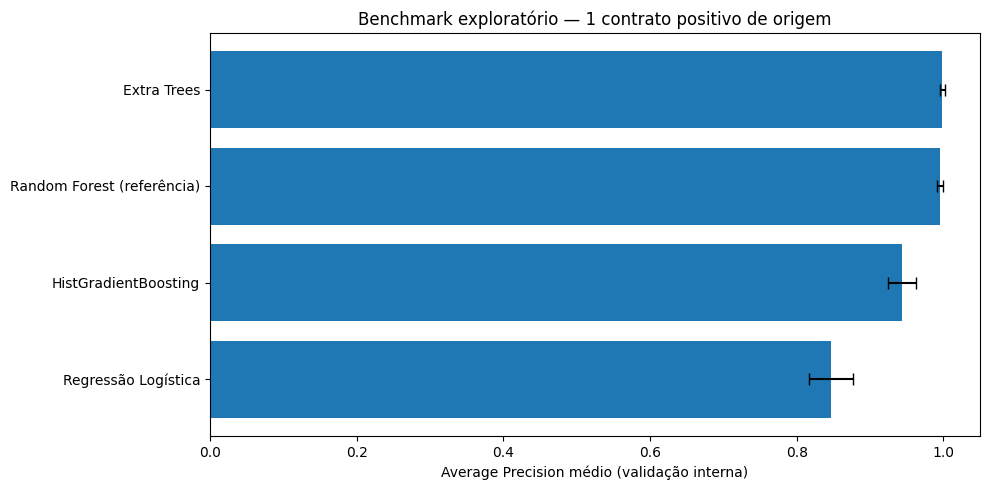

Arquivos gerados:
 • benchmark_ap.png
 • benchmark_resumo.csv
 • cv_folds.csv
 • cv_por_semente.csv
 • manifesto.json
 • relatorio.md


In [8]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,5))
ordenado=resumo.sort_values('ap_medio')
ax.barh(ordenado.index,ordenado.ap_medio,xerr=ordenado.ap_desvio,capsize=4)
ax.set_xlim(0,1.05);ax.set_xlabel('Average Precision médio (validação interna)')
ax.set_title('Benchmark exploratório — 1 contrato positivo de origem')
fig.tight_layout()
fig.savefig(OUT/'benchmark_ap.png',dpi=160)
plt.show()
relatorio=f"""# Experimento 10 — relatório exploratório

- Dataset: `{DATA}`
- SHA256: `{DATA_SHA256}`
- Amostras: {len(df)}; classes: {df.label.value_counts().to_dict()}
- Protocolo: {len(SEEDS)} sementes × {N_FOLDS} folds × {len(criar_modelos(42))} modelos
- Escopo: **validação cruzada por linha**, com reamostragem apenas no treino.

## Limitações

1. As amostras positivas são provenientes do mesmo contrato Tornado Cash 10 ETH, observado em dias diferentes. A validação cruzada por linha não testa generalização para contratos novos.
2. A avaliação não utiliza o teste de 2026 na seleção dos modelos; o teste de janeiro de 2026 já foi inspecionado e não deve ser tratado como intocado.
3. Não foram realizados ensemble/voting ou tuning no conjunto externo.

## Resultados

{resumo.round(4).to_markdown()}

**Interpretação:** o melhor desempenho nesta tabela indica apenas desempenho superior **na validação interna exploratória**. Necessário coletar exemplos positivos de outros contratos para validar por grupo.
"""
(OUT/'relatorio.md').write_text(relatorio,encoding='utf-8')
print('Arquivos gerados:')
for f in sorted(OUT.iterdir()):print(' •',f.name)


## 8 · Exportar resultados, se necessário
Se usou upload manual, execute a célula abaixo para baixar um ZIP. Com Drive, todos os CSVs e o relatório já estão gravados na pasta de resultados.

In [9]:
import zipfile
ZIP=OUT.parent/(OUT.name+'.zip')
with zipfile.ZipFile(ZIP,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        if p.is_file(): z.write(p,arcname=p.name)
print('ZIP:',ZIP)
# Para baixar no Colab, descomente:
# from google.colab import files
# files.download(str(ZIP))


ZIP: /content/drive/MyDrive/mixers-ethereum/results/10_benchmark_refatorado/20261115_004242_0a8baa11ce.zip


## Próxima etapa de pesquisa
Repetir com vários pools positivos e contratados negativos rotulados, usando **divisão por contrato** e mantendo um novo período externo intocado. Usar as métricas exploratórias para levantar hipóteses, não para anunciar superioridade definitiva.